# Lab 2: Music Genre Classification - CNNs
- **Task 1**: CNN desde cero sobre los espectrogramas mel, probando distintas profundidades y nº de filtros.
- **Task 2**: ResNet18 preentrenada en ImageNet (embeddings congelados + LogReg, y fine-tuning completo).
- **Research questions Q1, Q2 y Q5**, comparando con los modelos del Lab 1 reentrenados sobre la misma partición 80/20.

Pensado para GPU NVIDIA (`pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126` + `pandas scikit-learn seaborn pillow`).

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'Data'
SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'  # precisión mixta: ~2x más rápido en GPU
torch.backends.cudnn.benchmark = True

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

print(torch.cuda.get_device_name(0) if AMP else 'Sin GPU: va a ir lento')

NVIDIA GeForce RTX 3050


## Carga de los espectrogramas
Los PNG (432×288) llevan un marco blanco de matplotlib que se recorta. Se preparan dos versiones:
- **CNN desde cero**: escala de grises a 109×168. *Magma* es monótono en luminancia, así que el gris conserva la intensidad.
- **ResNet18**: RGB 224×224 normalizado como en ImageNet.

Son 999 canciones (`jazz.00054` está corrupto en GTZAN). Todo cabe en la GPU en float16 (~320 MB), así que no hace falta `DataLoader`.

In [2]:
CROP = (54, 35, 390, 253)  # caja del espectrograma dentro del PNG
img_dir = os.path.join(DATA_DIR, 'images_original')
GENRES = sorted(g for g in os.listdir(img_dir) if os.path.isdir(os.path.join(img_dir, g)))  # ignora .DS_Store
meta = pd.DataFrame([(os.path.join(img_dir, g, f), g, f.replace(g, g + '.').replace('.png', '.wav'))  # blues00000.png -> blues.00000.wav
                     for g in GENRES for f in sorted(os.listdir(os.path.join(img_dir, g))) if f.endswith('.png')],
                    columns=['path', 'genre', 'song'])
le = LabelEncoder()
y = le.fit_transform(meta['genre'])
genre_names = le.classes_

imgs = [Image.open(p).convert('RGB').crop(CROP) for p in meta['path']]
gray = torch.tensor(np.stack([np.array(im.convert('L').resize((168, 109))) for im in imgs]))[:, None] / 255
rgb = torch.tensor(np.stack([np.array(im.resize((224, 224))) for im in imgs])).permute(0, 3, 1, 2) / 255
rgb = (rgb - torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)) / torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

DTYPE = torch.float16 if AMP else torch.float32
X_small, X_224 = gray.to(DEVICE, DTYPE), rgb.to(DEVICE, DTYPE)
Y = torch.tensor(y, device=DEVICE).long()
del imgs, gray, rgb
print(len(meta), 'canciones |', tuple(X_small.shape), tuple(X_224.shape))

999 canciones | (999, 1, 109, 168) (999, 3, 224, 224)


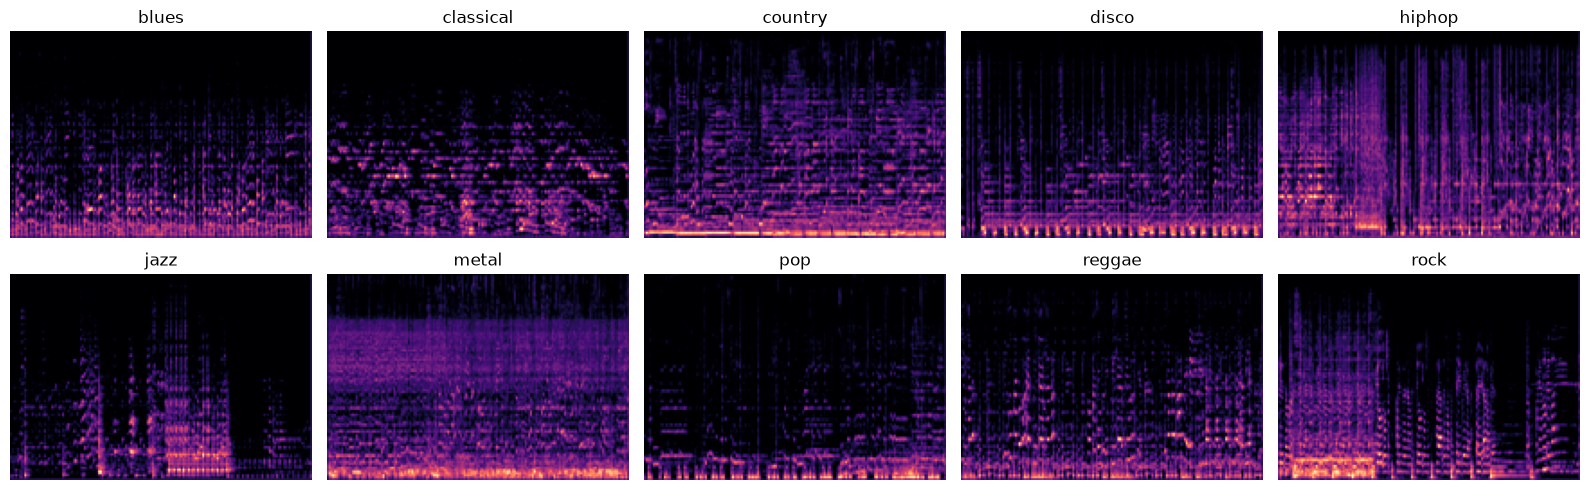

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for ax, g in zip(axes.flat, GENRES):
    ax.imshow(X_small[(meta['genre'] == g).idxmax(), 0].float().cpu(), cmap='magma', aspect='auto')
    ax.set_title(g); ax.axis('off')
plt.tight_layout(); plt.show()

## Partición 80/20 y utilidades
Partición estratificada y barajada 80% train / 20% test (200 canciones), **la misma para todos los modelos**. Para elegir configuraciones sin mirar el test, el 80% se vuelve a dividir 80/20 en train interno / validación (que también marca el *early stopping*).

Entrenamiento: Adam + cross-entropy con LR en coseno; se guardan los pesos de la mejor época en validación. Como *augmentation* se hace un desplazamiento circular en el eje temporal; no se usan *flips* porque invertir tiempo o frecuencia no tiene sentido musical.

In [4]:
def make_split(seed):
    tr_all, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    tr, va = train_test_split(tr_all, test_size=0.2, stratify=y[tr_all], random_state=seed)
    return tr_all, tr, va, te

idx_train, idx_tr, idx_val, idx_test = make_split(SEED)
y_test = y[idx_test]
results, test_preds = [], {}
print(f'Train {len(idx_train)} ({len(idx_tr)} + {len(idx_val)} val) | Test {len(idx_test)}')

def batches(X, idx, bs, shuffle=False):
    idx = torch.as_tensor(idx, device=DEVICE)
    if shuffle:
        idx = idx[torch.randperm(len(idx), device=DEVICE)]
    for i in range(0, len(idx), bs):
        yield X[idx[i:i + bs]], Y[idx[i:i + bs]]

@torch.no_grad()
def outputs(model, X, idx, bs=64):
    model.eval()
    with torch.autocast(DEVICE.type, enabled=AMP):
        return torch.cat([model(xb).float() for xb, _ in batches(X, idx, bs)]).cpu().numpy()

def predict(model, X, idx):
    return outputs(model, X, idx).argmax(1)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def train_model(model, X, tr, va, epochs=60, lr=1e-3, bs=32, patience=15):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)  # el LR baja poco a poco: curvas de validación menos ruidosas
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best_acc, best_epoch, wait = [], -1, 0, 0
    shift = X.shape[-1] // 4
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in batches(X, tr, bs, shuffle=True):
            xb = torch.roll(xb, random.randint(-shift, shift), dims=-1)  # el género no cambia si la canción empieza antes o después
            with torch.autocast(DEVICE.type, enabled=AMP):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()
        val_acc = accuracy_score(y[va], predict(model, X, va))
        hist.append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch, wait = val_acc, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        elif (wait := wait + 1) >= patience:
            break
    model.load_state_dict(best_state)
    return model, hist, best_epoch, best_acc

def grid_eval(model, params, X, tr, te, folds=5):
    # Escalado + búsqueda de hiperparámetros con CV dentro de train, evaluación en test
    grid = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('clf', model)]),
                        {f'clf__{k}': v for k, v in params.items()},
                        cv=StratifiedKFold(folds, shuffle=True, random_state=SEED), n_jobs=-1)
    grid.fit(X[tr], y[tr])
    pred = grid.predict(X[te])
    return grid, pred, accuracy_score(y[te], pred)

def add_result(name, family, pred, params=np.nan, seconds=np.nan):
    test_preds[name] = pred
    results.append({'Modelo': name, 'Familia': family, 'Test acc': accuracy_score(y_test, pred),
                    'Parámetros': params, 'Tiempo train (s)': seconds})

Train 799 (639 + 160 val) | Test 200


---
# Task 1: CNN desde cero
Bloques `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`, duplicando filtros en cada bloque. La cabeza es *Global Average Pooling* → Dropout → Linear: evita la capa densa enorme y deja muy pocos parámetros, que es lo que pide un train de ~640 canciones.

Se prueban **2-5 capas convolucionales** con **16 o 32 filtros** iniciales y se elige por accuracy de **validación**.

In [5]:
def simple_cnn(n_conv, f0):
    layers, ch = [], 1
    for i in range(n_conv):
        layers += [nn.Conv2d(ch, f0 * 2**i, 3, padding=1), nn.BatchNorm2d(f0 * 2**i), nn.ReLU(), nn.MaxPool2d(2)]
        ch = f0 * 2**i
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(ch, 10))

grid_rows, cnn_runs = [], {}
for n_conv in [2, 3, 4, 5]:
    for f0 in [16, 32]:
        set_seed()
        t0 = time.time()
        model, hist, epoch, acc = train_model(simple_cnn(n_conv, f0), X_small, idx_tr, idx_val)
        cnn_runs[n_conv, f0] = (model, hist)
        grid_rows.append({'Capas conv': n_conv, 'Filtros iniciales': f0, 'Parámetros': n_params(model),
                          'Mejor época': epoch, 'Val acc': acc, 'Tiempo (s)': time.time() - t0})

# En caso de empate en validación, gana la red más pequeña
grid_df = pd.DataFrame(grid_rows).sort_values(['Val acc', 'Parámetros'], ascending=[False, True], ignore_index=True)
grid_df.round(3)

,Capas conv,Filtros iniciales,Parámetros,Mejor época,Val acc,Tiempo (s)
0,4,16,98922,47,0.781,12.974
1,4,32,391370,33,0.769,17.692
2,5,16,395882,55,0.769,12.497
3,5,32,1575114,49,0.769,27.905
4,3,32,94410,43,0.731,18.600
5,3,16,24170,45,0.681,12.989
6,2,32,19658,29,0.556,17.690
7,2,16,5226,50,0.525,18.917


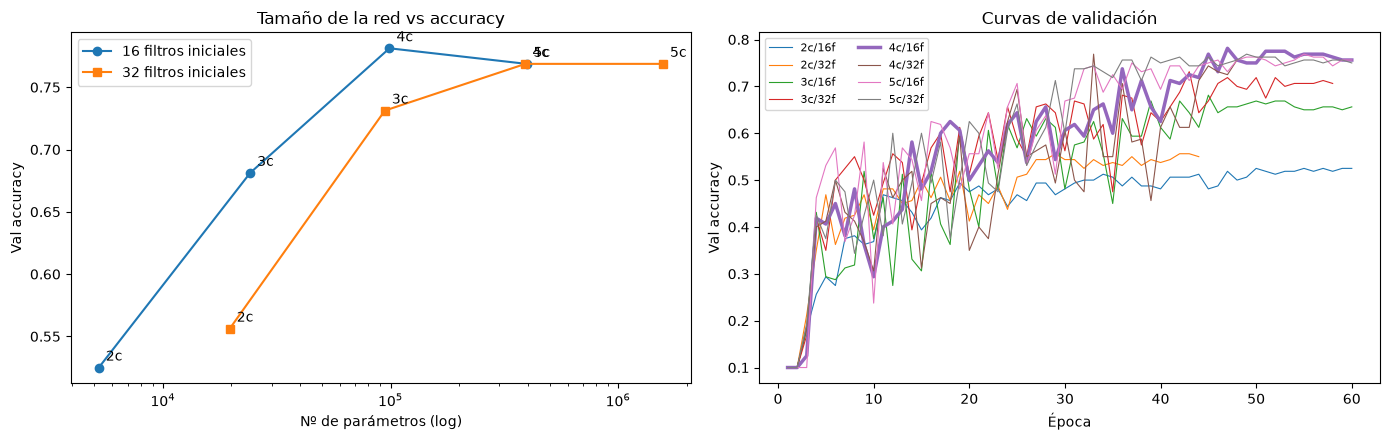

In [6]:
best_cfg = tuple(int(v) for v in grid_df.loc[0, ['Capas conv', 'Filtros iniciales']])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for f0, mk in [(16, 'o'), (32, 's')]:
    sub = grid_df[grid_df['Filtros iniciales'] == f0].sort_values('Parámetros')
    axes[0].plot(sub['Parámetros'], sub['Val acc'], marker=mk, label=f'{f0} filtros iniciales')
    for _, r in sub.iterrows():
        axes[0].annotate(f"{int(r['Capas conv'])}c", (r['Parámetros'], r['Val acc']), textcoords='offset points', xytext=(5, 5))
axes[0].set(xscale='log', xlabel='Nº de parámetros (log)', ylabel='Val accuracy', title='Tamaño de la red vs accuracy')
axes[0].legend()
for cfg, (_, hist) in cnn_runs.items():
    axes[1].plot(range(1, len(hist) + 1), hist, lw=2.5 if cfg == best_cfg else 0.8, label=f'{cfg[0]}c/{cfg[1]}f')
axes[1].set(xlabel='Época', ylabel='Val accuracy', title='Curvas de validación')
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

Evaluación única en test de la configuración elegida:

In [7]:
best_row = grid_df.loc[0]
cnn_name = f'CNN {best_cfg[0]} capas / {best_cfg[1]} filtros'
add_result(cnn_name, 'CNN desde cero', predict(cnn_runs[best_cfg][0], X_small, idx_test),
           best_row['Parámetros'], best_row['Tiempo (s)'])
print(f'{cnn_name}: test acc = {results[-1]["Test acc"]:.3f}')

CNN 4 capas / 16 filtros: test acc = 0.780


---
# Task 2: ResNet18 preentrenada (ImageNet)
1. **Embeddings congelados + regresión logística**: la red solo extrae un vector de 512 dimensiones por canción (salida del GAP) y encima se entrena una LogReg, como en el Lab 1.
2. **Fine-tuning completo**: se cambia la capa final por una de 10 géneros y se reentrena toda la red con un *learning rate* bajo para no destrozar lo aprendido. Misma validación y early stopping que en la Task 1.

In [8]:
backbone = torchvision.models.resnet18(weights='IMAGENET1K_V1', progress=False)
backbone.fc = nn.Identity()
t0 = time.time()
emb = outputs(backbone.to(DEVICE), X_224, np.arange(len(y)))  # embedding de 512 por canción
LOGREG_GRID = {'C': [0.001, 0.01, 0.1, 1]}
grid, pred, acc = grid_eval(LogisticRegression(max_iter=2000), LOGREG_GRID, emb, idx_train, idx_test)
add_result('ResNet18 congelada + LogReg', 'Preentrenado (congelado)', pred, n_params(backbone), time.time() - t0)
print(f'Congelada: CV acc = {grid.best_score_:.3f} {grid.best_params_} | test acc = {acc:.3f}')

def resnet18_ft():
    model = torchvision.models.resnet18(weights='IMAGENET1K_V1', progress=False)
    model.fc = nn.Linear(512, 10)
    return model

def finetune(tr, va, seed=SEED):
    set_seed(seed)
    return train_model(resnet18_ft(), X_224, tr, va, epochs=20, lr=1e-4, patience=5)

t0 = time.time()
ft_model, ft_hist, epoch, val_acc = finetune(idx_tr, idx_val)
add_result('ResNet18 fine-tuning', 'Preentrenado (fine-tuning)', predict(ft_model, X_224, idx_test),
           n_params(ft_model), time.time() - t0)
print(f'Fine-tuning: val acc = {val_acc:.3f} (época {epoch}) | test acc = {results[-1]["Test acc"]:.3f}')
del backbone, ft_model
torch.cuda.empty_cache()

Congelada: CV acc = 0.667 {'clf__C': 0.01} | test acc = 0.745


Fine-tuning: val acc = 0.800 (época 8) | test acc = 0.805


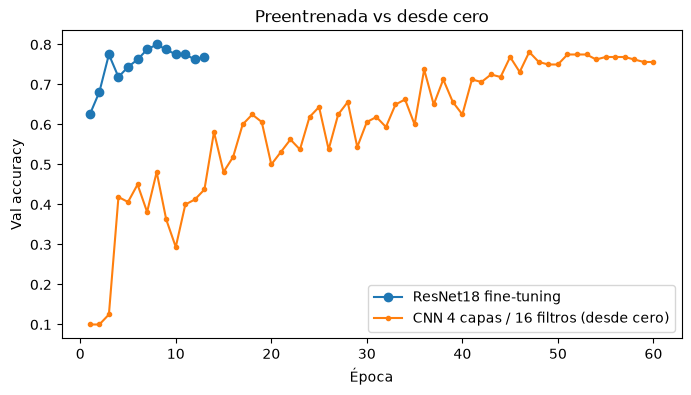

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ft_hist) + 1), ft_hist, marker='o', label='ResNet18 fine-tuning')
plt.plot(range(1, len(cnn_runs[best_cfg][1]) + 1), cnn_runs[best_cfg][1], marker='.', label=f'{cnn_name} (desde cero)')
plt.xlabel('Época'); plt.ylabel('Val accuracy'); plt.title('Preentrenada vs desde cero'); plt.legend(); plt.show()

---
# Research questions
Primero se reentrenan los modelos del Lab 1 sobre la **misma partición**: mismos algoritmos y rejillas, sobre `features_30_sec.csv`, con CV de 5 *folds* dentro del 80% de train y evaluación en las mismas 200 canciones.

In [10]:
df30 = pd.read_csv(os.path.join(DATA_DIR, 'features_30_sec.csv')).set_index('filename').loc[meta['song']]  # mismo orden que las imágenes
assert (df30['label'].values == meta['genre'].values).all()
X_desc = df30.drop(columns=['label', 'length']).values

lab1_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), {'C': [0.1, 1, 10]}),
    'k-NN': (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7], 'weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED), {'n_estimators': [50, 100], 'max_depth': [None, 10]}),
    'ANN': (MLPClassifier(max_iter=500, random_state=SEED), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.0001, 0.001]}),
}
lab1_cv = {}
for name, (model, params) in lab1_models.items():
    t0 = time.time()
    grid, pred, acc = grid_eval(model, params, X_desc, idx_train, idx_test)
    lab1_cv[name] = grid.best_score_
    add_result(f'{name} (Lab 1)', 'Descriptores Lab 1', pred, seconds=time.time() - t0)
    print(f'{name}: CV acc = {grid.best_score_:.3f} | test acc = {acc:.3f}')

# El mejor modelo de descriptores se elige por CV, no mirando el test
best_lab1 = max(lab1_cv, key=lab1_cv.get)
best_lab1_name = f'{best_lab1} (Lab 1)'
print('Mejor modelo de descriptores (por CV):', best_lab1)

Logistic Regression: CV acc = 0.700 | test acc = 0.690


k-NN: CV acc = 0.687 | test acc = 0.630


Decision Tree: CV acc = 0.504 | test acc = 0.495


Random Forest: CV acc = 0.708 | test acc = 0.660


ANN: CV acc = 0.730 | test acc = 0.755
Mejor modelo de descriptores (por CV): ANN


## Q1. ¿Las features aprendidas superan a los descriptores manuales?
Todos los modelos sobre el mismo test de 200 canciones (1 canción = 0.5 puntos).

,Modelo,Familia,Test acc,Parámetros,Tiempo train (s)
0,ResNet18 fine-tuning,Preentrenado (fine-tuning),0.805,"11,181,642",44.9
1,CNN 4 capas / 16 filtros,CNN desde cero,0.780,"98,922",13.0
2,ANN (Lab 1),Descriptores Lab 1,0.755,-,6.5
3,ResNet18 congelada + LogReg,Preentrenado (congelado),0.745,"11,176,512",18.9
4,Logistic Regression (Lab 1),Descriptores Lab 1,0.690,-,0.1
5,Random Forest (Lab 1),Descriptores Lab 1,0.660,-,1.2
6,k-NN (Lab 1),Descriptores Lab 1,0.630,-,0.3
7,Decision Tree (Lab 1),Descriptores Lab 1,0.495,-,0.2


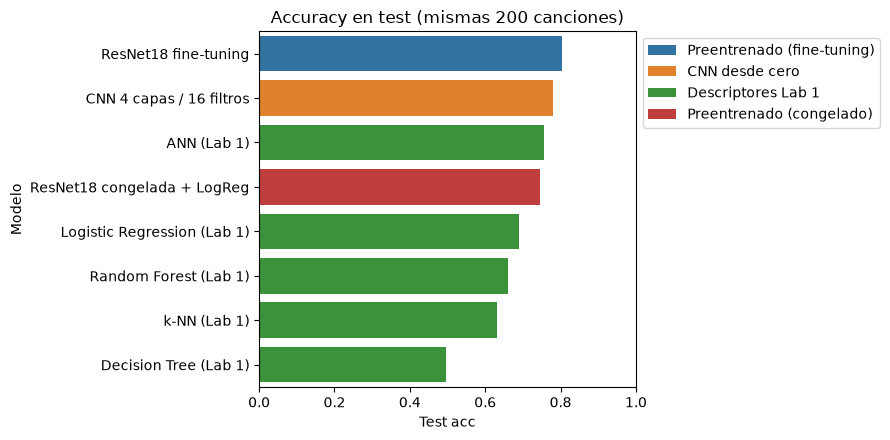

In [11]:
summary = pd.DataFrame(results).sort_values('Test acc', ascending=False, ignore_index=True)
display(summary.style.format({'Test acc': '{:.3f}', 'Parámetros': '{:,.0f}', 'Tiempo train (s)': '{:.1f}'}, na_rep='-'))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=summary, y='Modelo', x='Test acc', hue='Familia', dodge=False, ax=ax)
ax.set_xlim(0, 1); ax.set_title('Accuracy en test (mismas 200 canciones)'); ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

**Respuesta Q1:** **En esta partición sí, pero por poco.** En las mismas 200 canciones de test, la ResNet18 con fine-tuning (0.805) y la CNN desde cero (0.780) superan al mejor modelo de descriptores, la ANN (0.755), por 10 y 5 canciones respectivamente. Los demás modelos del Lab 1 quedan claramente por debajo: LogReg 0.690, Random Forest 0.660, k-NN 0.630 y árbol 0.495.

Que las features sean aprendidas no basta: tienen que aprenderse **para esta tarea**. Los embeddings congelados de ImageNet con LogReg (0.745) no llegan a la ANN sobre descriptores. ImageNet aprende formas y texturas de fotos, no patrones tiempo-frecuencia. En cambio, una CNN pequeña de 99k parámetros entrenada desde cero con solo 639 canciones alcanza o supera a 57 descriptores diseñados a mano.

Hay una salvedad importante: las diferencias son de 5-10 canciones y, como se ve en la Q5, al repetir con otras particiones los tres mejores modelos quedan empatados (~0.74-0.75). La conclusión honesta es que **las features aprendidas igualan a los descriptores, pero no los superan de forma clara** con un dataset de este tamaño.

## Q2. ¿Las CNNs y los modelos de descriptores cometen los mismos errores?
Se comparan la CNN desde cero, la ResNet18 con fine-tuning y el mejor modelo de descriptores: matrices de confusión, solapamiento de errores y pares de géneros más confundidos.

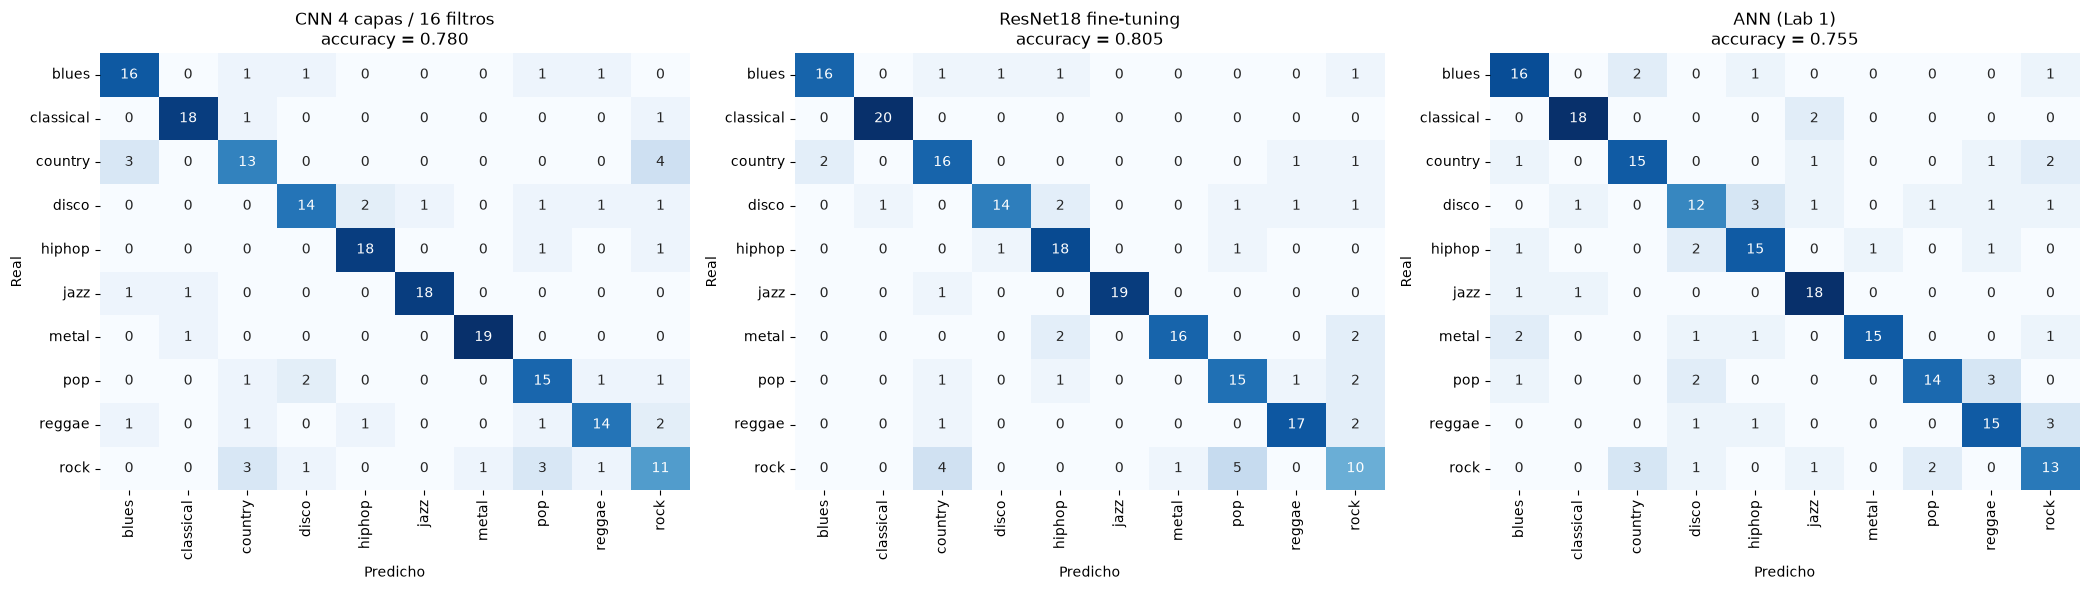

In [12]:
shown = [cnn_name, 'ResNet18 fine-tuning', best_lab1_name]
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, name in zip(axes, shown):
    sns.heatmap(confusion_matrix(y_test, test_preds[name]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=genre_names, yticklabels=genre_names)
    ax.set(title=f'{name}\naccuracy = {accuracy_score(y_test, test_preds[name]):.3f}', xlabel='Predicho', ylabel='Real')
plt.tight_layout(); plt.show()

In [13]:
errors = {name: test_preds[name] != y_test for name in shown}
overlap = []
for i, a in enumerate(shown):
    for b in shown[i + 1:]:
        both, either = (errors[a] & errors[b]).sum(), (errors[a] | errors[b]).sum()
        overlap.append({'A': a, 'B': b, 'Errores A': errors[a].sum(), 'Errores B': errors[b].sum(), 'Fallan ambos': both,
                        'Jaccard': both / either, 'Oráculo (acierta alguno)': 1 - both / len(y_test)})
display(pd.DataFrame(overlap).round(3))

def top_confusions(pred, k=5):
    cm = confusion_matrix(y_test, pred)
    cm = cm + cm.T  # contamos la confusión en ambos sentidos
    pairs = sorted(((cm[i, j], f'{genre_names[i]} ↔ {genre_names[j]}') for i in range(10) for j in range(i + 1, 10)), reverse=True)
    return [f'{p} ({n})' for n, p in pairs[:k]]

pd.DataFrame({name: top_confusions(test_preds[name]) for name in shown}, index=range(1, 6))

,A,B,Errores A,Errores B,Fallan ambos,Jaccard,Oráculo (acierta alguno)
0,CNN 4 capas / 16 filtros,ResNet18 fine-tuning,44,39,25,0.431,0.875
1,CNN 4 capas / 16 filtros,ANN (Lab 1),44,49,23,0.329,0.885
2,ResNet18 fine-tuning,ANN (Lab 1),39,49,18,0.257,0.910


,CNN 4 capas / 16 filtros,ResNet18 fine-tuning,ANN (Lab 1)
1,country ↔ rock (7),pop ↔ rock (7),disco ↔ hiphop (5)
2,pop ↔ rock (4),country ↔ rock (5),country ↔ rock (5)
3,blues ↔ country (4),metal ↔ rock (3),reggae ↔ rock (3)
4,reggae ↔ rock (3),disco ↔ hiphop (3),pop ↔ reggae (3)
5,disco ↔ pop (3),blues ↔ country (3),disco ↔ pop (3)


**Respuesta Q2:** **Solo en parte.** Las tres matrices de confusión comparten la estructura gruesa: classical y jazz se reconocen bien en los tres modelos (18-20 de 20), **rock está entre los géneros más difíciles** en todos (10-13 de 20) y **country ↔ rock** aparece entre los pares más confundidos de los tres. Esta parte de la estructura de similitud del Lab 1 es propia de la música: rock, country y pop comparten instrumentación (guitarras, batería, voz) y tempo.

El resto de errores sí depende de la representación. Las dos redes que ven el espectrograma confunden sobre todo **pop ↔ rock** y blues ↔ country, géneros con un timbre global parecido. La ANN sobre descriptores confunde **disco ↔ hiphop** (su par más frecuente) y pop ↔ reggae, y su género más difícil es disco (12 de 20); son géneros que coinciden en estadísticos de ritmo y energía (tempo, RMS, centroide) aunque su espectrograma sea distinto. Por tanto, parte de la estructura de similitud del Lab 1 se debe a los descriptores.

El solapamiento de errores lo confirma. Las dos CNNs fallan juntas en 25 canciones (Jaccard 0.43), pero cada CNN y la ANN solo comparten 18-23 errores (Jaccard 0.26-0.33). Si un oráculo eligiese en cada canción el modelo que acierta, ResNet18 + ANN llegaría a 0.910, 10 puntos más que el mejor modelo solo. Los dos enfoques son, por tanto, bastante complementarios.

## Q5. ¿Cuánto dice una sola partición 80/20?
Con 200 canciones de test, la diferencia entre dos modelos en una única partición puede ser ruido. Se repite todo con **5 particiones** (semillas 0-4), manteniendo fija la configuración de cada modelo. Los embeddings congelados ya están calculados, así que solo se reentrena la LogReg.

In [14]:
SEEDS = range(5)
lab1_model, lab1_params = lab1_models[best_lab1]
seed_rows = []
for seed in SEEDS:
    tr_all, tr, va, te = make_split(seed)
    set_seed(seed)
    cnn = train_model(simple_cnn(*best_cfg), X_small, tr, va)[0]
    ft = finetune(tr, va, seed)[0]
    accs = {cnn_name: accuracy_score(y[te], predict(cnn, X_small, te)),
            'ResNet18 fine-tuning': accuracy_score(y[te], predict(ft, X_224, te)),
            'ResNet18 congelada + LogReg': grid_eval(LogisticRegression(max_iter=2000), LOGREG_GRID, emb, tr_all, te)[2],
            best_lab1_name: grid_eval(lab1_model, lab1_params, X_desc, tr_all, te)[2]}
    seed_rows += [{'Semilla': seed, 'Modelo': m, 'Test acc': a} for m, a in accs.items()]
    print(seed, {m: round(a, 3) for m, a in accs.items()})
    del cnn, ft
    torch.cuda.empty_cache()
seed_df = pd.DataFrame(seed_rows)

0 {'CNN 4 capas / 16 filtros': 0.725, 'ResNet18 fine-tuning': 0.815, 'ResNet18 congelada + LogReg': 0.665, 'ANN (Lab 1)': 0.795}


1 {'CNN 4 capas / 16 filtros': 0.74, 'ResNet18 fine-tuning': 0.75, 'ResNet18 congelada + LogReg': 0.7, 'ANN (Lab 1)': 0.74}


2 {'CNN 4 capas / 16 filtros': 0.735, 'ResNet18 fine-tuning': 0.65, 'ResNet18 congelada + LogReg': 0.685, 'ANN (Lab 1)': 0.715}


3 {'CNN 4 capas / 16 filtros': 0.72, 'ResNet18 fine-tuning': 0.775, 'ResNet18 congelada + LogReg': 0.7, 'ANN (Lab 1)': 0.785}


4 {'CNN 4 capas / 16 filtros': 0.765, 'ResNet18 fine-tuning': 0.755, 'ResNet18 congelada + LogReg': 0.66, 'ANN (Lab 1)': 0.69}


,mean,std,min,max,rango (canciones)
Modelo,,,,,
ResNet18 fine-tuning,0.749,0.061,0.65,0.815,33
ANN (Lab 1),0.745,0.045,0.69,0.795,21
CNN 4 capas / 16 filtros,0.737,0.018,0.72,0.765,9
ResNet18 congelada + LogReg,0.682,0.019,0.66,0.700,8


,Diferencia media vs Lab 1,Std diferencia,Gana en (de 5)
Modelo,,,
CNN 4 capas / 16 filtros,-0.008,0.061,2
ResNet18 congelada + LogReg,-0.063,0.044,0
ResNet18 fine-tuning,0.004,0.047,3


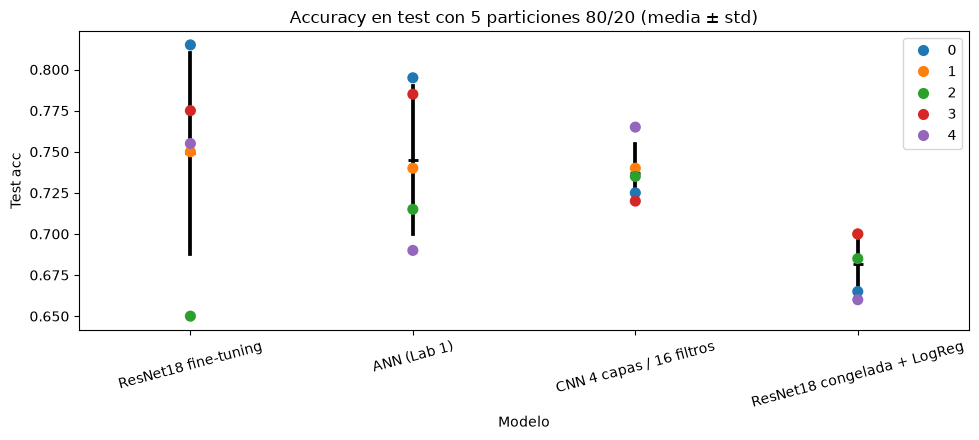

In [15]:
stats = seed_df.groupby('Modelo')['Test acc'].agg(['mean', 'std', 'min', 'max']).sort_values('mean', ascending=False)
stats['rango (canciones)'] = ((stats['max'] - stats['min']) * len(idx_test)).round().astype(int)
display(stats.round(3))

# Diferencias pareadas frente al mejor modelo de descriptores en cada partición
pivot = seed_df.pivot(index='Semilla', columns='Modelo', values='Test acc')
diff = pivot.drop(columns=best_lab1_name).sub(pivot[best_lab1_name], axis=0)
display(pd.DataFrame({'Diferencia media vs Lab 1': diff.mean(), 'Std diferencia': diff.std(),
                      'Gana en (de 5)': (diff > 0).sum()}).round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(data=seed_df, x='Modelo', y='Test acc', order=stats.index, hue='Semilla', palette='tab10', size=8, jitter=False, ax=ax)
sns.pointplot(data=seed_df, x='Modelo', y='Test acc', order=stats.index, color='black', markers='_', errorbar='sd', linestyles='none', ax=ax)
ax.set_title('Accuracy en test con 5 particiones 80/20 (media ± std)'); ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

**Respuesta Q5:** **Muy poco.** Se repitió todo con 5 particiones distintas (semillas 0-4), manteniendo fija la configuración de cada modelo. Las medias quedan prácticamente empatadas: ResNet18 fine-tuning 0.749 ± 0.061, ANN sobre descriptores 0.745 ± 0.045 y CNN desde cero 0.737 ± 0.018. La ordenación de la semilla 42 (fine-tuning > CNN > ANN) no se mantiene: en las diferencias pareadas frente a la ANN, el fine-tuning gana en 3 de 5 particiones (+0.004 de media) y la CNN en 2 de 5 (-0.008). Las dos diferencias son mucho menores que su desviación (~0.05), así que no son significativas.

La variabilidad entre particiones es grande. El fine-tuning va de 0.650 a 0.815, una diferencia de 33 canciones o 16 puntos, mientras que la diferencia entre los tres mejores modelos en la semilla 42 era de solo 10 canciones. La CNN pequeña es, junto a los embeddings congelados, el modelo más estable (rango de 9 canciones); el fine-tuning, con 11M parámetros y 639 canciones, es el que más depende de qué canciones caen en train, validación y test.

Hay además otra fuente de ruido: el entrenamiento en GPU no es determinista (cuDNN). En una ejecución anterior del mismo notebook, con la misma semilla, la configuración elegida fue 4 capas / 32 filtros con 0.830 en test, y en esta es 4 capas / 16 filtros con 0.780. Con 200 canciones de test, cada canción vale 0.5 puntos y diferencias menores de ~5 puntos no permiten afirmar que un modelo es mejor que otro.

La única conclusión robusta es que **los embeddings congelados de ImageNet son peores**: 0.682 ± 0.019, por debajo de la ANN en las 5 particiones (-0.063 de media).